In [21]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)


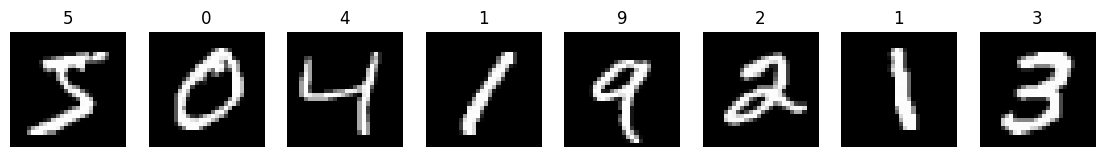

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import struct, time

def load_images(path):
    with open(path, 'rb') as f:
        _, n, r, c = struct.unpack('>IIII', f.read(16))  # f.read(16), тк читаем 16 байт, размерность (60000, 28, 28)
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, r, c)

def load_labels(path):
    with open(path, 'rb') as f:
        struct.unpack('>II', f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

base = '/kaggle/input/datasets/hojjatk/mnist-dataset/'
X_train_img = load_images(base + 'train-images.idx3-ubyte')
y_train     = load_labels(base + 'train-labels.idx1-ubyte')
X_test_img  = load_images(base + 't10k-images.idx3-ubyte')
y_test      = load_labels(base + 't10k-labels.idx1-ubyte')

print('Train:', X_train_img.shape, y_train.shape)
print('Test: ', X_test_img.shape, y_test.shape)

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_img[i], cmap='gray'); ax.set_title(f'{y_train[i]}'); ax.axis('off')
plt.show()

In [23]:
X_train = X_train_img.reshape(-1, 784).astype(np.float32) / 255.0
X_test  = X_test_img.reshape(-1, 784).astype(np.float32) / 255.0

def one_hot(y, k=10):
    out = np.zeros((len(y), k), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

Y_train, Y_test = one_hot(y_train), one_hot(y_test)
print(X_train.shape, Y_train.shape, X_train.min(), X_train.max())

(60000, 784) (60000, 10) 0.0 1.0


In [24]:
class Mnist_NN:
    def __init__(self, n_in=784, n_hidden=300, n_out=10, seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = (rng.standard_normal((n_in, n_hidden)) * np.sqrt(2.0 / n_in)).astype(np.float32)
        self.b1 = np.zeros(n_hidden, dtype=np.float32)
        self.W2 = (rng.standard_normal((n_hidden, n_out)) * np.sqrt(2.0 / n_hidden)).astype(np.float32)
        self.b2 = np.zeros(n_out, dtype=np.float32)

    def softmax(self, z):
        z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def cross_entropy(self, P, Y):
        return -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))

    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = np.maximum(0, self.Z1)  # ReLu
        self.P = self.softmax(self.A1 @ self.W2 + self.b2)
        return self.P

    def backward(self, Y):
        B = self.X.shape[0]
        dZ2 = (self.P - Y) / B  #  от sofmax
        self.dW2 = self.A1.T @ dZ2
        self.db2 = dZ2.sum(axis=0)
        dZ1 = (dZ2 @ self.W2.T) * (self.Z1 > 0)  # relu
        self.dW1 = self.X.T @ dZ1
        self.db1 = dZ1.sum(axis=0)

    def step(self, lr):
        self.W1 -= lr * self.dW1
        self.b1 -= lr * self.db1
        self.W2 -= lr * self.dW2
        self.b2 -= lr * self.db2

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

    def error_rate(self, X, y):
        return np.mean(self.predict(X) != y)


net = Mnist_NN()
P = net.forward(X_train[:64])
print('loss:', net.cross_entropy(P, Y_train[:64]))

loss: 2.4317899


In [25]:
lr, batch_size, epochs, s = 0.1, 32, 20, 300

net = Mnist_NN(n_hidden=s) 
rng = np.random.default_rng(0)
history = {'loss': [], 'train_err': [], 'test_err': []}

for epoch in range(1, epochs + 1):
    t0 = time.time()
    idx = rng.permutation(len(X_train))
    total_loss, nb = 0.0, 0

    for i in range(0, len(idx), batch_size):
        b = idx[i:i + batch_size]
        Xb, Yb = X_train[b], Y_train[b]
        P = net.forward(Xb)
        total_loss += net.cross_entropy(P, Yb); nb += 1
        net.backward(Yb)
        net.step(lr)

    tr_err = net.error_rate(X_train, y_train)
    te_err = net.error_rate(X_test, y_test)
    history['loss'].append(total_loss / nb)
    history['train_err'].append(tr_err)
    history['test_err'].append(te_err)
    print(f'Epoch {epoch:2d}/{epochs} | loss {total_loss/nb:.4f} | '
          f'Error train {tr_err*100:.2f}% | time {time.time()-t0:.1f} c')

Epoch  1/20 | loss 0.2822 | Error train 4.18% | time 2.6 c
Epoch  2/20 | loss 0.1333 | Error train 3.00% | time 2.5 c
Epoch  3/20 | loss 0.0932 | Error train 1.91% | time 2.7 c
Epoch  4/20 | loss 0.0720 | Error train 1.60% | time 2.6 c
Epoch  5/20 | loss 0.0578 | Error train 1.16% | time 2.5 c
Epoch  6/20 | loss 0.0476 | Error train 1.09% | time 2.5 c
Epoch  7/20 | loss 0.0396 | Error train 0.78% | time 2.7 c
Epoch  8/20 | loss 0.0332 | Error train 0.53% | time 2.5 c
Epoch  9/20 | loss 0.0277 | Error train 0.50% | time 2.6 c
Epoch 10/20 | loss 0.0234 | Error train 0.42% | time 2.5 c
Epoch 11/20 | loss 0.0196 | Error train 0.24% | time 2.8 c
Epoch 12/20 | loss 0.0170 | Error train 0.22% | time 2.7 c
Epoch 13/20 | loss 0.0144 | Error train 0.12% | time 2.7 c
Epoch 14/20 | loss 0.0123 | Error train 0.11% | time 2.8 c
Epoch 15/20 | loss 0.0106 | Error train 0.06% | time 2.5 c
Epoch 16/20 | loss 0.0092 | Error train 0.04% | time 2.6 c
Epoch 17/20 | loss 0.0080 | Error train 0.05% | time 2.7

Error Test: 1.77%  (acc 98.23%)


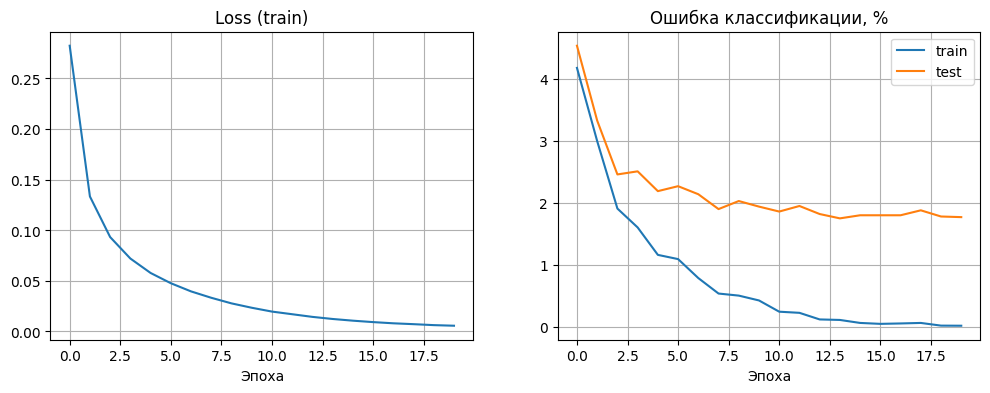

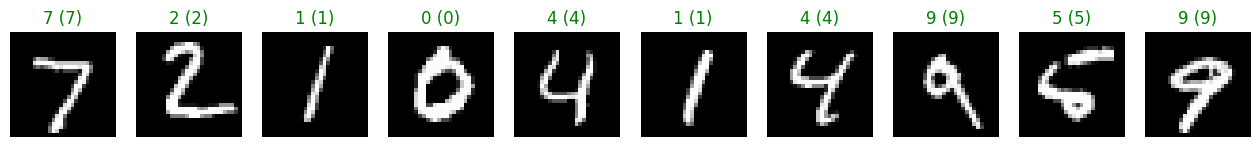

In [26]:
test_err = error_rate(p, X_test, y_test)
print(f'Error Test: {test_err*100:.2f}%  (acc {100-test_err*100:.2f}%)')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(history['loss']); a1.set_title('Loss (train)'); a1.set_xlabel('Эпоха'); a1.grid()
a2.plot(np.array(history['train_err'])*100, label='train')
a2.plot(np.array(history['test_err'])*100, label='test')
a2.set_title('Ошибка классификации, %'); a2.set_xlabel('Эпоха'); a2.legend(); a2.grid()
plt.show()

pred = forward(p, X_test[:10])[2].argmax(axis=1)
fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_test_img[i], cmap='gray'); ax.axis('off')
    ax.set_title(f'{pred[i]} ({y_test[i]})', color='green' if pred[i] == y_test[i] else 'red')
plt.show()